In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
pip install openpyxl

Note: you may need to restart the kernel to use updated packages.


In [3]:
from pathlib import Path

folder = Path("Exercise on shared mobility/02_Voi")
files = sorted(folder.glob("*.xlsx"))
df_list = [pd.read_excel(f) for f in files]
data_voi_raw = pd.concat(df_list, ignore_index=True)
print("Files:", len(files))
print("Rows:", data_voi_raw.shape[0], "Columns:", data_voi_raw.shape[1])

Files: 22
Rows: 291765 Columns: 13


In [5]:
data_voi_raw.head()

,Identificativo noleggio,Targa veicolo,Data inizio corsa,Data fine corsa,Lat inizio corsa_coordinate,Lon inizio corsa_coordinate,Lat fine corsa_coordinate,Lon fine corsa_coordinate,Tempo Tot,KM Tot,Prenotazione,Batteria inizio,Batteria fine
0,7dd196a9-9888-40ad-9095-4c8218526c20,m974,20240100000000,20240100000000,45.059769,7.679094,45.077547,7.681845,8.916667,1.988588,No,58.0,50.0
1,78303ff3-2574-4a91-bbb7-87f6a042ee51,jgty,20240100000000,20240100000000,45.068397,7.656463,45.071265,7.653724,4.033333,0.384634,No,83.0,79.0
2,2f430fb2-09b7-4610-b9df-ed66a12871af,dkhj,20240100000000,20240100000000,45.081652,7.660944,45.078108,7.669140,2.666667,0.754599,No,62.0,58.0
3,6281d533-3832-4066-9850-92d1eac01173,hp6q,20240100000000,20240100000000,45.062248,7.679739,45.065672,7.641323,15.466667,3.041097,No,86.0,73.0
4,4460dd97-8b20-4f43-a5d7-7c2bfdf46412,3nhd,20240100000000,20240100000000,45.069775,7.667012,45.059175,7.671873,6.116667,1.239007,No,78.0,74.0


In [6]:
rename_dict_voi = {
    "Identificativo noleggio": "rental_id",
    "Targa veicolo": "vehicle_id",
    "Data inizio corsa": "start_datetime",
    "Data fine corsa": "end_datetime",
    "Lat inizio corsa_coordinate": "start_latitude",
    "Lon inizio corsa_coordinate": "start_longitude",
    "Lat fine corsa_coordinate": "end_latitude",
    "Lon fine corsa_coordinate": "end_longitude",
    "Tempo Tot": "duration_min",
    "KM Tot": "distance_km",
    "Prenotazione": "is_reserved",
    "Batteria inizio": "battery_start_pct",
    "Batteria fine": "battery_end_pct"
}
data_voi_raw = data_voi_raw.rename(columns=rename_dict_voi)
data_voi_raw.head()

,rental_id,vehicle_id,start_datetime,end_datetime,start_latitude,start_longitude,end_latitude,end_longitude,duration_min,distance_km,is_reserved,battery_start_pct,battery_end_pct
0,7dd196a9-9888-40ad-9095-4c8218526c20,m974,20240100000000,20240100000000,45.059769,7.679094,45.077547,7.681845,8.916667,1.988588,No,58.0,50.0
1,78303ff3-2574-4a91-bbb7-87f6a042ee51,jgty,20240100000000,20240100000000,45.068397,7.656463,45.071265,7.653724,4.033333,0.384634,No,83.0,79.0
2,2f430fb2-09b7-4610-b9df-ed66a12871af,dkhj,20240100000000,20240100000000,45.081652,7.660944,45.078108,7.669140,2.666667,0.754599,No,62.0,58.0
3,6281d533-3832-4066-9850-92d1eac01173,hp6q,20240100000000,20240100000000,45.062248,7.679739,45.065672,7.641323,15.466667,3.041097,No,86.0,73.0
4,4460dd97-8b20-4f43-a5d7-7c2bfdf46412,3nhd,20240100000000,20240100000000,45.069775,7.667012,45.059175,7.671873,6.116667,1.239007,No,78.0,74.0


In [7]:
data_voi_raw.isnull().sum()

rental_id               0
vehicle_id              0
start_datetime          0
end_datetime            0
start_latitude          0
start_longitude         0
end_latitude           87
end_longitude          87
duration_min            0
distance_km            87
is_reserved             0
battery_start_pct    6001
battery_end_pct      6001
dtype: int64

In [8]:
data_voi_raw.shape

(291765, 13)

In [9]:
data_voi_raw.tail(10).to_csv('my_data_sample_tail.csv', index=False)

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- EXERCISE 1: VOI CLEANING & PLOTTING (Using Loaded Data) ---

print("🚀 Starting Voi Analysis on 'data_voi_raw'...")

# 1. Create a copy to avoid changing the original raw data
if 'data_voi_raw' in locals():
    df_voi = data_voi_raw.copy()
    print(f"Loaded from memory. Original Rows: {len(df_voi)}")
else:
    print("❌ Error: 'data_voi_raw' not found in memory!")
    # Stop execution if variable is missing (Uncomment below line if testing with file)
    # df_voi = pd.read_csv("voi_september.csv") 

🚀 Starting Voi Analysis on 'data_voi_raw'...
Loaded from memory. Original Rows: 291765


In [11]:
# 2. THE CRITICAL FIX: Force convert to String first!
# This fixes the bug where Python reads '20240100...' as a number (nanoseconds from 1970)
df_voi['start_datetime'] = df_voi['start_datetime'].astype(str)
df_voi['end_datetime'] = df_voi['end_datetime'].astype(str)

In [13]:
# 3. Parse Dates
# errors='coerce' turns bad strings (like '20240100...') into NaT
df_voi['start_datetime'] = pd.to_datetime(df_voi['start_datetime'], errors='error')
df_voi['end_datetime'] = pd.to_datetime(df_voi['end_datetime'], errors='error')

In [14]:
# 4. Filter Valid Data
# Remove NaT rows
df_voi_clean = df_voi.dropna(subset=['start_datetime', 'end_datetime']).copy()

# Remove any lingering 1970 dates (just in case)
df_voi_clean = df_voi_clean[df_voi_clean['start_datetime'].dt.year > 2020]

print(f"✅ Cleaned Rows: {len(df_voi_clean)}")
print(f"🗑️ Removed Rows: {len(df_voi) - len(df_voi_clean)}")
if len(df_voi_clean) > 0:
    print(f"📅 Date Range: {df_voi_clean['start_datetime'].min()}  TO  {df_voi_clean['start_datetime'].max()}")

✅ Cleaned Rows: 285639
🗑️ Removed Rows: 6126
📅 Date Range: 2024-01-31 23:03:35  TO  2025-10-31 22:56:24


In [15]:
# 5. Extract Features for Plotting
df_voi_clean['date'] = df_voi_clean['start_datetime'].dt.date
df_voi_clean['day_of_week'] = df_voi_clean['start_datetime'].dt.day_name()
df_voi_clean['month_name'] = df_voi_clean['start_datetime'].dt.month_name()
df_voi_clean['hour'] = df_voi_clean['start_datetime'].dt.hour

In [16]:
# Convert Datetime
# Standard conversion. Errors='coerce' will turn unparseable formats into NaT
df_voi_clean['start_datetime'] = pd.to_datetime(df_voi_clean['start_datetime'], errors='error')
df_voi_clean['end_datetime'] = pd.to_datetime(df_voi_clean['end_datetime'], errors='error')

In [25]:
# --- STEP 1:
cols_to_check = [
    'start_datetime', 'end_datetime',
    'start_latitude', 'start_longitude',
    'end_latitude', 'end_longitude',
    'battery_start_pct', 'battery_end_pct'
]

if 'distance_km' in df_voi_clean.columns:
    cols_to_check.append('distance_km')

df_voi_clean = df_voi_clean.dropna(subset=cols_to_check)

if 'duration_min' in df_voi_clean.columns:
    df_voi_clean = df_voi_clean[df_voi_clean['duration_min'] > 0].copy()

print("\n--- FINAL CLEANING CHECK ---")
print(f"✅ Final Dataset Size: {len(df_voi_clean)} rows")
print("Remaining Missing Values:\n", df_voi_clean.isnull().sum())


--- FINAL CLEANING CHECK ---
✅ Final Dataset Size: 279536 rows
Remaining Missing Values:
 rental_id            0
vehicle_id           0
start_datetime       0
end_datetime         0
start_latitude       0
start_longitude      0
end_latitude         0
end_longitude        0
duration_min         0
distance_km          0
is_reserved          0
battery_start_pct    0
battery_end_pct      0
date                 0
day_of_week          0
month_name           0
hour                 0
dtype: int64


In [26]:
# --- STEP 2: LOGICAL ERROR CLEANING (VOI) ---

print("Starting Logical Error Cleaning...")

# 1. Identify "Zero Displacement" Trips (Start Location == End Location)
# These are likely cancelled trips or GPS errors where the user didn't move
zero_displacement_mask = (df_voi_clean['start_latitude'] == df_voi_clean['end_latitude']) & \
                         (df_voi_clean['start_longitude'] == df_voi_clean['end_longitude'])

num_zero_disp = zero_displacement_mask.sum()

# 2. Identify "Time Paradox" Trips (End Time < Start Time)
# It is impossible to end a trip before starting it
negative_time_mask = df_voi_clean['end_datetime'] < df_voi_clean['start_datetime']

num_neg_time = negative_time_mask.sum()

# 3. Report Statistics Before Dropping
print("\n--- 🔍 DIAGNOSIS REPORT ---")
print(f"Total Rows Before Logic Clean: {len(df_voi_clean)}")
print(f"❌ Zero Displacement Trips:     {num_zero_disp} rows")
print(f"❌ Negative Time Trips:         {num_neg_time} rows")

# 4. Remove the Invalid Rows
# We keep rows that are NOT zero displacement AND NOT negative time
df_voi_final = df_voi_clean[~zero_displacement_mask & ~negative_time_mask].copy()

print("\n--- ✅ FINAL CLEANING RESULTS ---")
print(f"Cleaned Dataset Size: {len(df_voi_final)} rows")
print(f"Total Removed in this step: {len(df_voi_clean) - len(df_voi_final)} rows")

# Update the main variable for next steps
df_voi_clean = df_voi_final.copy()

Starting Logical Error Cleaning...

--- 🔍 DIAGNOSIS REPORT ---
Total Rows Before Logic Clean: 279536
❌ Zero Displacement Trips:     207 rows
❌ Negative Time Trips:         0 rows

--- ✅ FINAL CLEANING RESULTS ---
Cleaned Dataset Size: 279329 rows
Total Removed in this step: 207 rows


In [169]:
df_voi_clean.shape

(279329, 17)

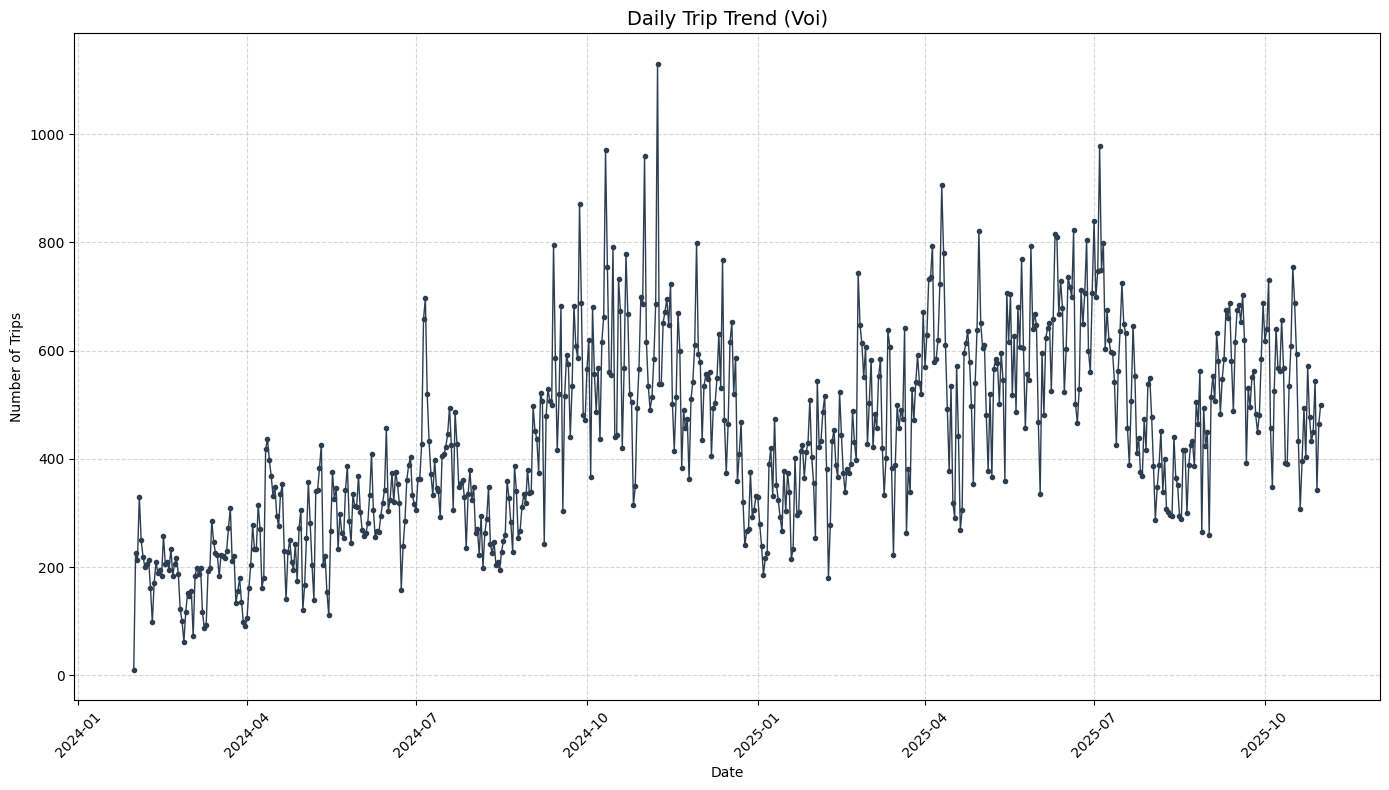

In [27]:
# --- PLOT 1: DAILY TREND  ---
plt.figure(figsize=(14, 8))
daily_counts = df_voi_clean.groupby('date').size()
daily_counts.plot(kind='line', marker='.', color='#2c3e50', linewidth=1)
plt.title('Daily Trip Trend (Voi)', fontsize=14)
plt.ylabel('Number of Trips')
plt.xlabel('Date')
plt.grid(True, linestyle='--', alpha=0.5)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

/var/folders/15/_z7w7n_55q3d5xdjvb552jtm0000gn/T/ipykernel_3043/1057447860.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  weekly_counts = df_voi_clean.groupby('day_of_week').size()


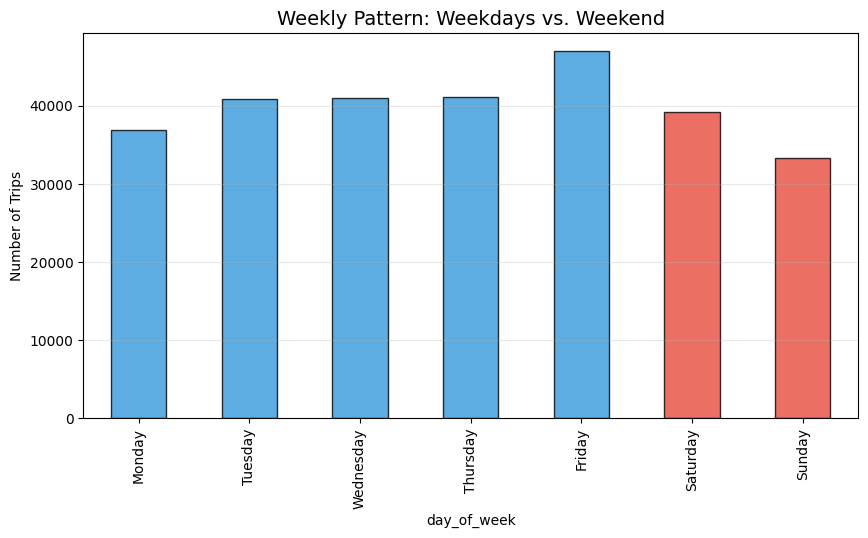

In [28]:
# --- PLOT 2: WEEKLY ANALYSIS ---
plt.figure(figsize=(10, 5))
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df_voi_clean['day_of_week'] = pd.Categorical(df_voi_clean['day_of_week'], categories=days_order, ordered=True)
weekly_counts = df_voi_clean.groupby('day_of_week').size()

colors = ['#3498db' if x < 5 else '#e74c3c' for x in range(7)] 
weekly_counts.plot(kind='bar', color=colors, alpha=0.8, edgecolor='black')
plt.title('Weekly Pattern: Weekdays vs. Weekend', fontsize=14)
plt.ylabel('Number of Trips')
plt.grid(axis='y', alpha=0.3)
plt.show()

--- Cleaned Monthly Data (Jan 2024 removed if < 100) ---


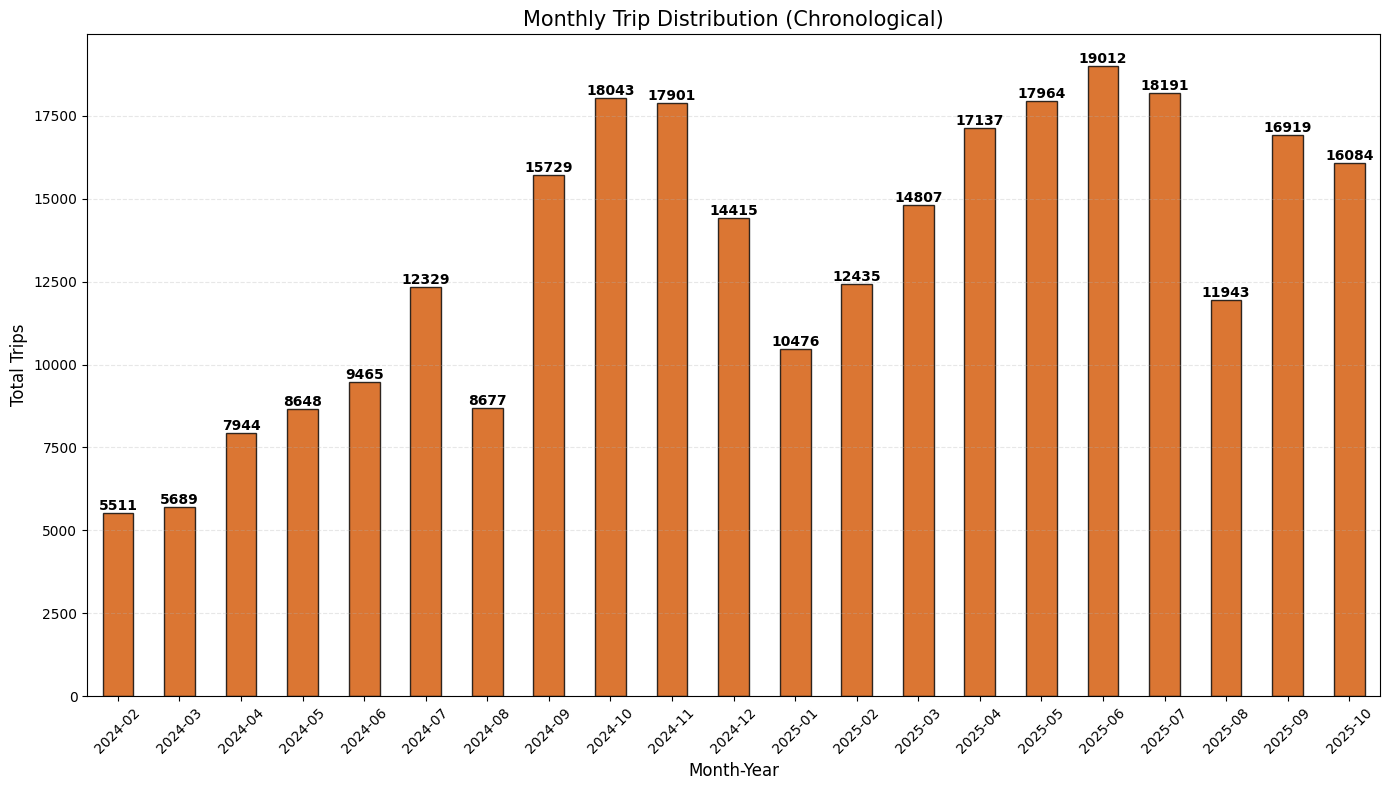

In [29]:
# --- PLOT 3: MONTHLY OVERVIEW ---
# 1. Create Period
df_voi_clean['month_year'] = df_voi_clean['start_datetime'].dt.to_period('M')

# 2. Filter out months with very little data (like Jan 2024 with only 10 trips)
# We calculate counts first
monthly_counts = df_voi_clean.groupby('month_year').size().sort_index()

# Filter: Only keep months with more than 100 trips (removes the noisy Jan 2024)
monthly_counts_clean = monthly_counts[monthly_counts > 100]

print("--- Cleaned Monthly Data (Jan 2024 removed if < 100) ---")


# 3. Plotting
plt.figure(figsize=(14, 8)) 
ax = monthly_counts_clean.plot(kind='bar', color='#d35400', edgecolor='black', alpha=0.8)

plt.title('Monthly Trip Distribution (Chronological)', fontsize=15)
plt.ylabel('Total Trips', fontsize=12)
plt.xlabel('Month-Year', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=45)

# Add value labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()


--- Valid Data for Comparison ---
year        2024   2025
month_num              
2           5511  12435
3           5689  14807
4           7944  17137
5           8648  17964
6           9465  19012
7          12329  18191
8           8677  11943
9          15729  16919
10         18043  16084


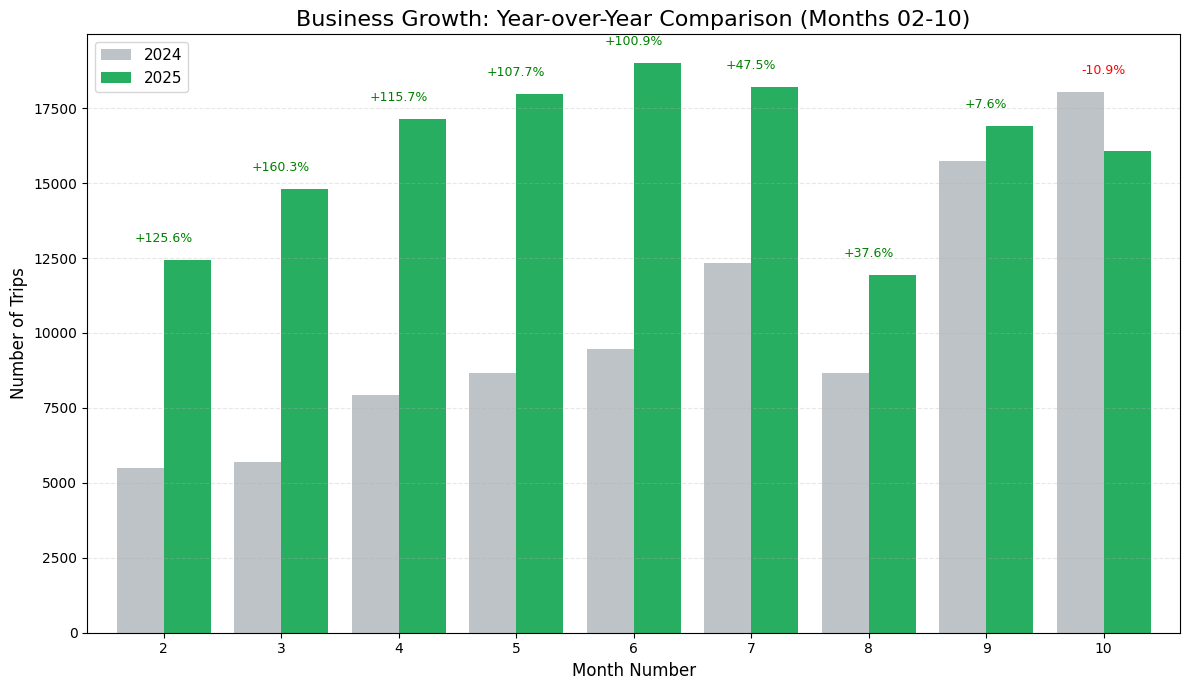

In [30]:
# 1. Prepare Data with Numeric Months
df_voi_clean['year'] = df_voi_clean['start_datetime'].dt.year
df_voi_clean['month_num'] = df_voi_clean['start_datetime'].dt.month

# 2. Filter Logic
# Keep only months 2 (February) through 10 (October)
df_filtered = df_voi_clean[(df_voi_clean['month_num'] >= 2) & (df_voi_clean['month_num'] <= 10)].copy()

# 3. Create Pivot Table
# Rows: Month Number | Columns: Year | Values: Count
pivot_data = df_filtered.groupby(['month_num', 'year']).size().unstack()

# Drop rows where any year is missing (Intersection)
pivot_data_clean = pivot_data.dropna()

print("\n--- Valid Data for Comparison ---")
print(pivot_data_clean)

# 4. PLOT
# Plot bar chart
ax = pivot_data_clean.plot(kind='bar', figsize=(12, 7), width=0.8, color=['#bdc3c7', '#27ae60']) 

plt.title('Business Growth: Year-over-Year Comparison (Months 02-10)', fontsize=16)
plt.ylabel('Number of Trips', fontsize=12)
plt.xlabel('Month Number', fontsize=12)
plt.legend(['2024', '2025'], fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.xticks(rotation=0)

# 5. Add Growth Percentage Labels
for i, month in enumerate(pivot_data_clean.index):
    val_2024 = pivot_data_clean.loc[month, 2024]
    val_2025 = pivot_data_clean.loc[month, 2025]
    
    # Calculate Growth
    growth_rate = ((val_2025 - val_2024) / val_2024) * 100
    
    # Dynamic Color: Green for positive, Red for negative
    text_color = 'green' if growth_rate >= 0 else 'red'
    
    # Format string using Python's {:+.1f} which handles signs automatically
    label_text = f"{growth_rate:+.1f}%"
    
    # Position text above the taller bar
    max_height = max(val_2024, val_2025)
    plt.text(i, max_height + 500, label_text, 
             ha='center', va='bottom', fontsize=9, color=text_color)

plt.tight_layout()
plt.show()

Generating Hourly Profile (Weekday vs Weekend)...


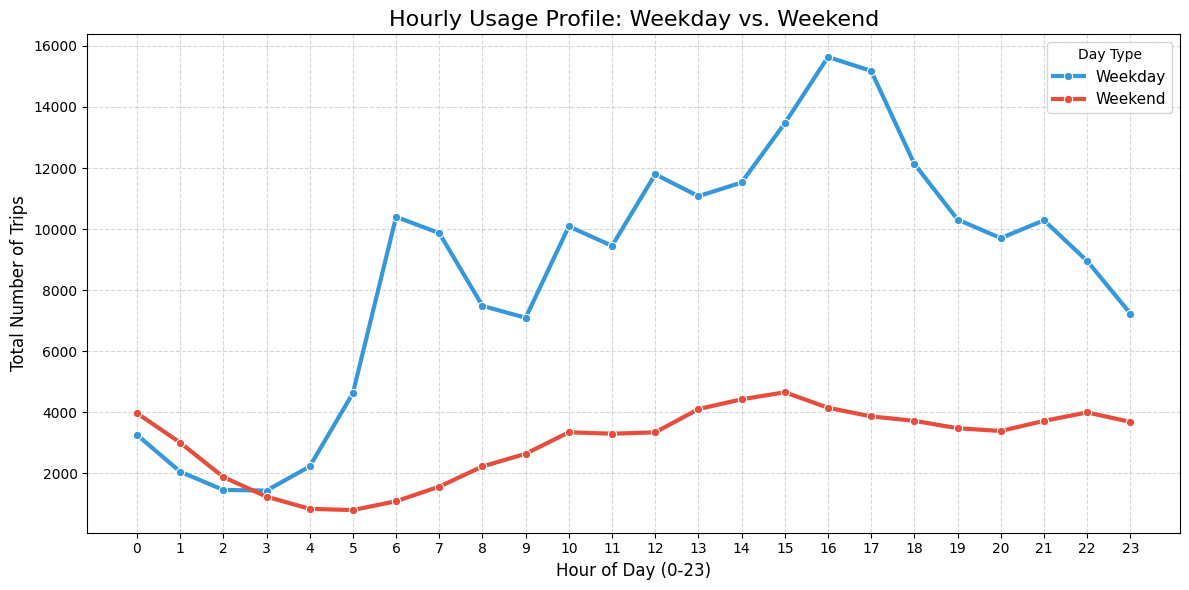

In [53]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- EXERCISE 1: MISSING CHART (HOURLY PROFILE) ---

print("Generating Hourly Profile (Weekday vs Weekend)...")

# 1. Prepare Data
# Create Hour and Day Type columns
df_voi_clean['hour'] = df_voi_clean['start_datetime'].dt.hour
df_voi_clean['day_name'] = df_voi_clean['start_datetime'].dt.day_name()

# Categorize as Weekday or Weekend
def get_day_type(day):
    if day in ['Saturday', 'Sunday']:
        return 'Weekend'
    else:
        return 'Weekday'

df_voi_clean['day_type'] = df_voi_clean['day_name'].apply(get_day_type)

# 2. Aggregation
# We calculate the total counts per hour for each type
hourly_trends = df_voi_clean.groupby(['hour', 'day_type']).size().reset_index(name='trip_count')

# 3. Plotting
plt.figure(figsize=(12, 6))

# Use Seaborn Lineplot for smooth comparison
sns.lineplot(data=hourly_trends, x='hour', y='trip_count', hue='day_type', 
             palette={'Weekday': '#3498db', 'Weekend': '#e74c3c'}, 
             linewidth=3, marker='o')

plt.title('Hourly Usage Profile: Weekday vs. Weekend', fontsize=16)
plt.xlabel('Hour of Day (0-23)', fontsize=12)
plt.ylabel('Total Number of Trips', fontsize=12)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Day Type', fontsize=11)

plt.tight_layout()
plt.show()

🔹 Converting Map CRS from EPSG:3003 to EPSG:4326...
✅ Map Loaded! Found 94 statistical zones.
🔹 Using column 'DENOM' for zone names.
📍 Performing Spatial Join (Mapping points to zones)...
✅ Trips successfully mapped: 278481


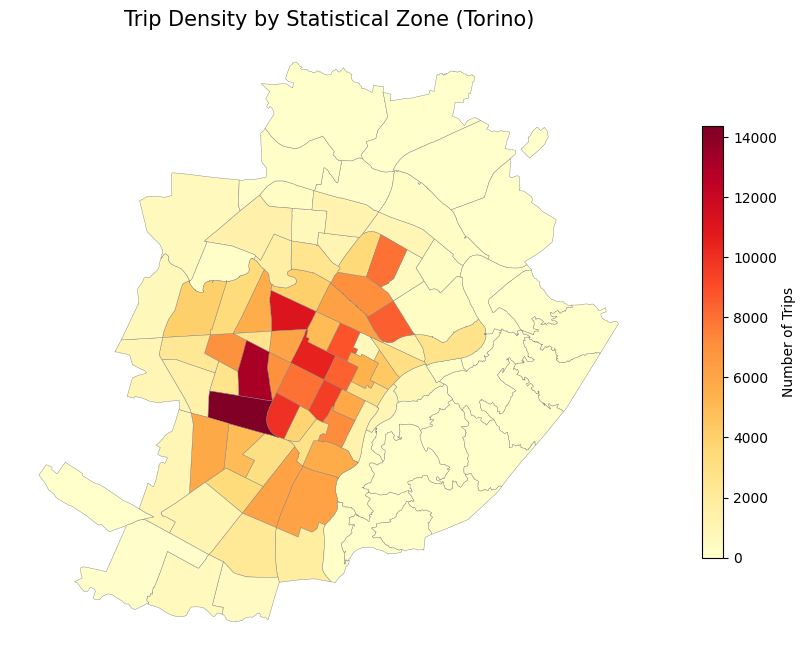

In [71]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from shapely.geometry import Point

# --- EXERCISE 2: SPATIAL ANALYSIS (VOI) - FINAL ---
# 1. SETUP: Load the Shapefile
# Use raw string (r"...") to handle spaces in the path correctly
# If files are in the same folder, just use "zone_statistiche_geo.shp"
shapefile_path = r"/Users/amirhosseinghaderi/Desktop/Third Semester/Transport/Projects/EX1/map/zone_statistiche_geo.shp"

try:
    gdf_zones = gpd.read_file(shapefile_path)
    
    # 2. CRS Conversion (CRITICAL STEP)
    # The Shapefile is likely in EPSG:3003 (Monte Mario), needs to be EPSG:4326 (Lat/Lon)
    if gdf_zones.crs != "EPSG:4326":
        print(f"🔹 Converting Map CRS from {gdf_zones.crs} to EPSG:4326...")
        gdf_zones = gdf_zones.to_crs("EPSG:4326")
    
    print(f"✅ Map Loaded! Found {len(gdf_zones)} statistical zones.")
    
    # Identify Zone Name Column (Based on your .dbf file, it's 'DENOM')
    zone_name_col = 'DENOM' 
    if zone_name_col not in gdf_zones.columns:
        # Fallback if DENOM isn't found
        zone_name_col = gdf_zones.columns[0]
        
    print(f"🔹 Using column '{zone_name_col}' for zone names.")

except Exception as e:
    print(f"❌ Error loading map: {e}")
    print("Try moving the .shp, .shx, .dbf files to the same folder as this notebook.")
    # Stop if map fails
    raise

# 3. SPATIAL JOIN: Map Trips to Zones
# Convert Voi Data to GeoDataFrames
geometry_start = [Point(xy) for xy in zip(df_voi_clean['start_longitude'], df_voi_clean['start_latitude'])]
gdf_voi_start = gpd.GeoDataFrame(df_voi_clean, geometry=geometry_start, crs="EPSG:4326")

geometry_end = [Point(xy) for xy in zip(df_voi_clean['end_longitude'], df_voi_clean['end_latitude'])]
gdf_voi_end = gpd.GeoDataFrame(df_voi_clean, geometry=geometry_end, crs="EPSG:4326")

print("📍 Performing Spatial Join (Mapping points to zones)...")

# Join Start Points
gdf_start_joined = gpd.sjoin(gdf_voi_start, gdf_zones[['geometry', zone_name_col]], how="inner", predicate="within")
gdf_start_joined.rename(columns={zone_name_col: 'start_zone'}, inplace=True)

# Join End Points
gdf_end_joined = gpd.sjoin(gdf_voi_end, gdf_zones[['geometry', zone_name_col]], how="inner", predicate="within")
gdf_end_joined.rename(columns={zone_name_col: 'end_zone'}, inplace=True)

# Combine back to main dataframe
df_spatial = df_voi_clean.copy()
# Use index matching to assign zones
df_spatial.loc[gdf_start_joined.index, 'start_zone'] = gdf_start_joined['start_zone']
df_spatial.loc[gdf_end_joined.index, 'end_zone'] = gdf_end_joined['end_zone']

# Drop trips outside the map
df_spatial = df_spatial.dropna(subset=['start_zone', 'end_zone'])
print(f"✅ Trips successfully mapped: {len(df_spatial)}")


# --- PLOT 1: TRIP DENSITY MAP (HEATMAP) ---
zone_counts = df_spatial['start_zone'].value_counts().reset_index()
zone_counts.columns = [zone_name_col, 'trip_count']

# Merge counts back to map
gdf_heatmap = gdf_zones.merge(zone_counts, on=zone_name_col, how='left').fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(14, 8))
gdf_heatmap.plot(column='trip_count', ax=ax, legend=True,
                 legend_kwds={'label': "Number of Trips", 'shrink': 0.7},
                 cmap='YlOrRd', edgecolor='gray', linewidth=0.3)

plt.title('Trip Density by Statistical Zone (Torino)', fontsize=15)
plt.axis('off')
plt.show()


📊 Generating O-D Matrix (Top 15 Zones)...


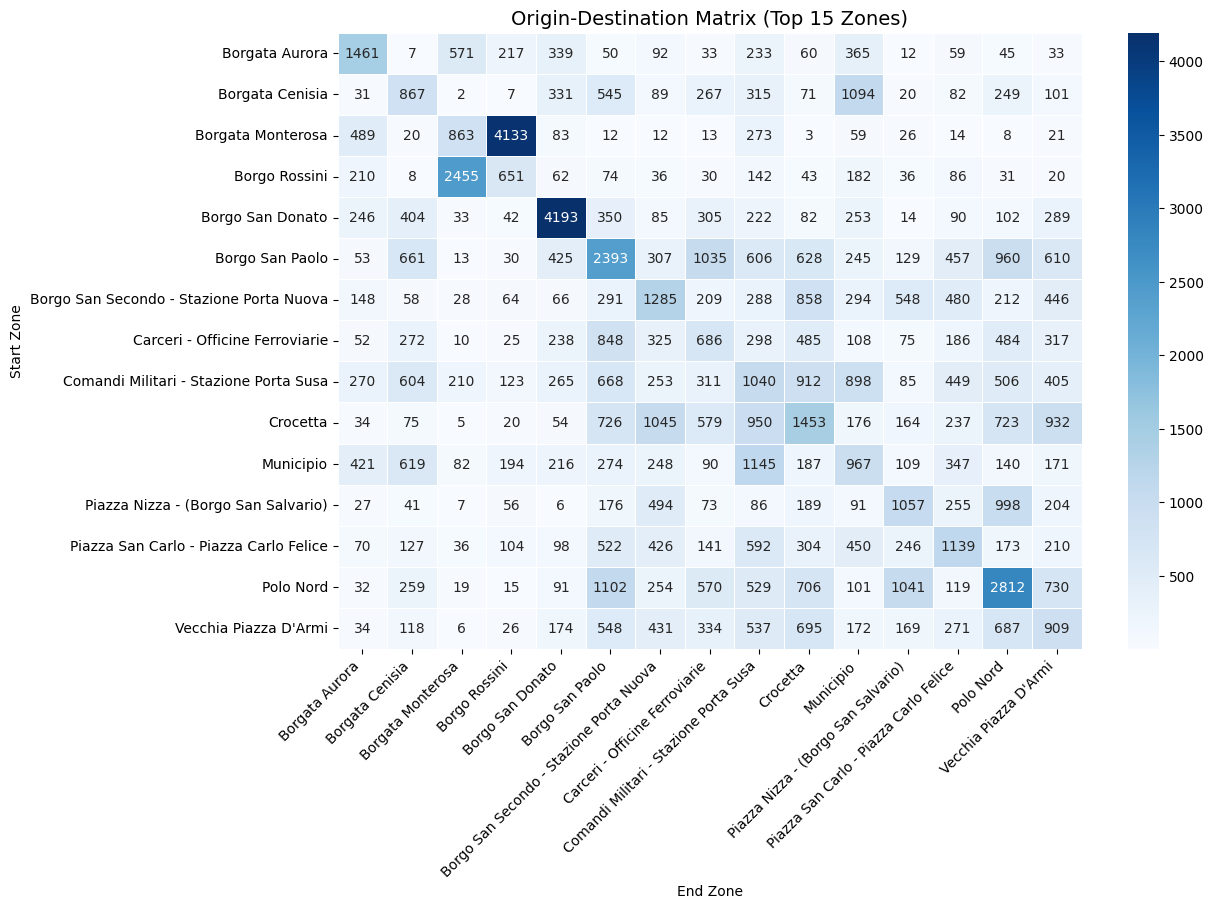

In [72]:
# --- PLOT 2: O-D MATRIX (Flow Intensity) ---
print("\n📊 Generating O-D Matrix (Top 15 Zones)...")

# Filter for top 15 busiest zones to make the matrix readable
top_15_zones = df_spatial['start_zone'].value_counts().head(15).index
df_top_od = df_spatial[df_spatial['start_zone'].isin(top_15_zones) & df_spatial['end_zone'].isin(top_15_zones)]

od_matrix = pd.crosstab(df_top_od['start_zone'], df_top_od['end_zone'])

plt.figure(figsize=(12, 8))
sns.heatmap(od_matrix, cmap="Blues", annot=True, fmt='d', linewidths=.5)
plt.title('Origin-Destination Matrix (Top 15 Zones)', fontsize=14)
plt.ylabel('Start Zone')
plt.xlabel('End Zone')
plt.xticks(rotation=45, ha='right')
plt.show()

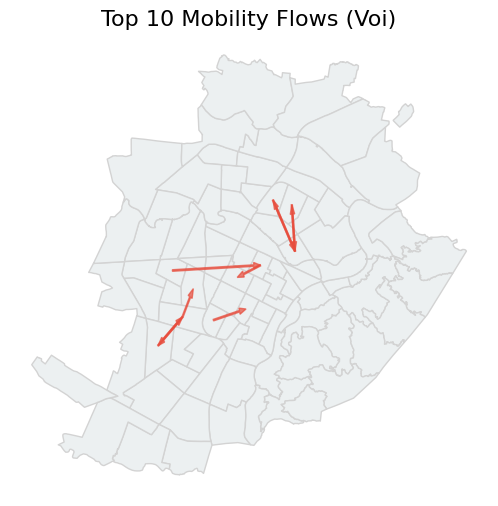

In [73]:
# --- PLOT 3: FLOW MAP (CORRECTED) ---
# 1. Calculate Centroids Correctly (Project to Meters first)
gdf_temp = gdf_zones.to_crs("EPSG:32632")
gdf_temp['centroid'] = gdf_temp.geometry.centroid

# Convert centroids back to GPS coordinates (EPSG:4326) for plotting
gdf_temp['centroid'] = gdf_temp['centroid'].to_crs("EPSG:4326")

# Create a dictionary for fast lookup: {Zone_Name: Point_Geometry}
centroid_dict = dict(zip(gdf_temp[zone_name_col], gdf_temp['centroid']))

# 2. Prepare Top Routes
route_counts = df_spatial.groupby(['start_zone', 'end_zone']).size().reset_index(name='count')
# Remove loops (start == end) to keep map clean
route_counts = route_counts[route_counts['start_zone'] != route_counts['end_zone']]
top_routes = route_counts.sort_values('count', ascending=False).head(10)

# 3. Plot
fig, ax = plt.subplots(1, 1, figsize=(10, 6))

# Plot the base map (Zones)
gdf_zones.plot(ax=ax, color='#ecf0f1', edgecolor='lightgray')

# Plot Arrows
for idx, row in top_routes.iterrows():
    start_z = row['start_zone']
    end_z = row['end_zone']
    
    # Retrieve pre-calculated centroids (Fast & Error-free)
    if start_z in centroid_dict and end_z in centroid_dict:
        start_geom = centroid_dict[start_z]
        end_geom = centroid_dict[end_z]
        
        # Draw arrow
        plt.arrow(start_geom.x, start_geom.y, 
                  end_geom.x - start_geom.x, end_geom.y - start_geom.y,
                  head_width=0.002, length_includes_head=True, 
                  color='#e74c3c', alpha=0.7, width=0.0005, zorder=5)

plt.title('Top 10 Mobility Flows (Voi)', fontsize=16)
plt.axis('off')
plt.show()

📊 Generating Zone Imbalance Chart...


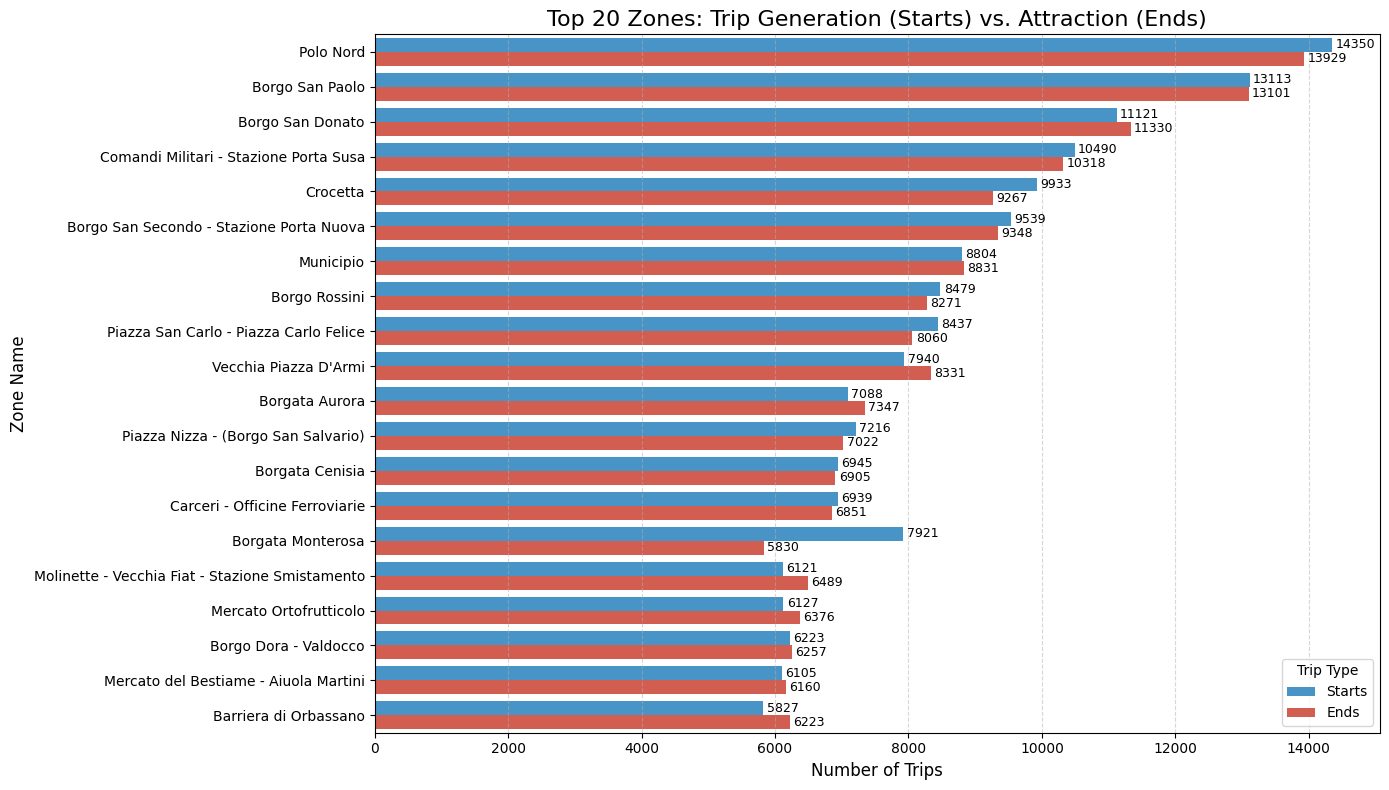


--- Zone Imbalance Insight (Top 5) ---
                                      Zone   Starts   Ends  Net_Flow
68                               Polo Nord  14350.0  13929    -421.0
24                         Borgo San Paolo  13113.0  13101     -12.0
22                        Borgo San Donato  11121.0  11330     209.0
30  Comandi Militari - Stazione Porta Susa  10490.0  10318    -172.0
33                                Crocetta   9933.0   9267    -666.0


In [52]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# --- EXERCISE 2: ZONE IMBALANCE CHART (STARTS vs ENDS) ---

print("📊 Generating Zone Imbalance Chart...")

# 1. Prepare Data
# Count trips starting in each zone
starts = df_spatial['start_zone'].value_counts().reset_index()
starts.columns = ['Zone', 'Starts']

# Count trips ending in each zone
ends = df_spatial['end_zone'].value_counts().reset_index()
ends.columns = ['Zone', 'Ends']

# Merge the two counts
zone_stats = pd.merge(starts, ends, on='Zone', how='outer').fillna(0)

# Calculate Total Activity (Starts + Ends) to find the busiest zones
zone_stats['Total'] = zone_stats['Starts'] + zone_stats['Ends']

# Sort by Total Activity and take top 20
top_zones = zone_stats.sort_values('Total', ascending=False).head(20)

# Melt for plotting (Make it suitable for Seaborn barplot)
top_zones_melted = top_zones.melt(id_vars='Zone', value_vars=['Starts', 'Ends'], 
                                  var_name='Type', value_name='Count')

# 2. Plot
plt.figure(figsize=(14, 8))

# Create grouped bar chart
sns.barplot(data=top_zones_melted, x='Count', y='Zone', hue='Type', 
            palette={'Starts': '#3498db', 'Ends': '#e74c3c'}, orient='h')

plt.title('Top 20 Zones: Trip Generation (Starts) vs. Attraction (Ends)', fontsize=16)
plt.xlabel('Number of Trips', fontsize=12)
plt.ylabel('Zone Name', fontsize=12)
plt.legend(title='Trip Type')
plt.grid(axis='x', linestyle='--', alpha=0.5)

# Add value labels specifically for "Starts" (Blue) and "Ends" (Red)
# This part is a bit manual in Seaborn but makes the chart pro
for p in plt.gca().patches:
    width = p.get_width()
    if width > 0: # Only label if bar exists
        plt.gca().text(width + 50, p.get_y() + p.get_height()/2, 
                       f'{int(width)}', va='center', fontsize=9, color='black')

plt.tight_layout()
plt.show()

# 3. Print Imbalance Table (Optional Insight)
top_zones['Net_Flow'] = top_zones['Ends'] - top_zones['Starts']
print("\n--- Zone Imbalance Insight (Top 5) ---")
print(top_zones[['Zone', 'Starts', 'Ends', 'Net_Flow']].head())

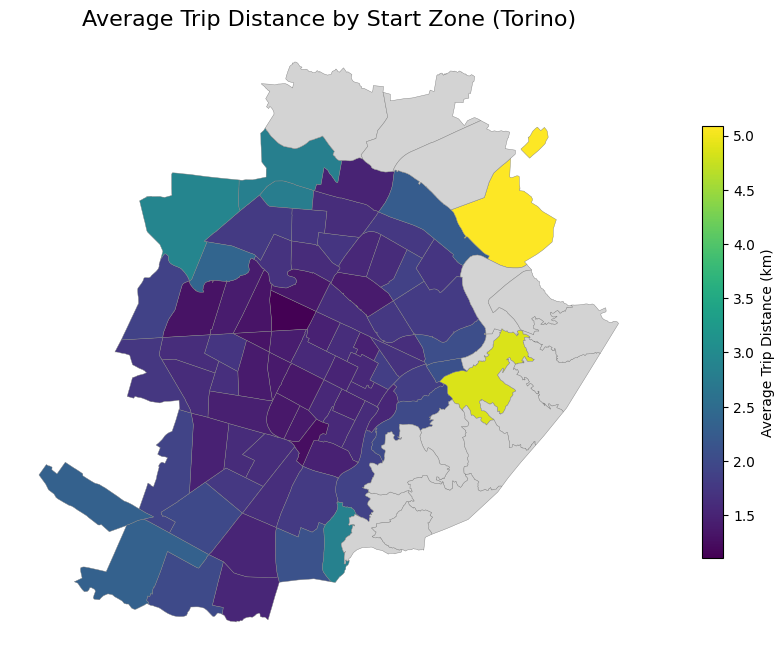

In [66]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --- EXERCISE 2: FINAL MAP (AVERAGE DISTANCE PER ZONE) ---
# 1. Calculate Average Distance per Zone
# We group by start zone and take the mean of 'distance_km'
avg_dist = df_spatial.groupby('start_zone')['distance_km'].mean().reset_index()
avg_dist.columns = ['DENOM', 'avg_distance_km'] # Using 'DENOM' to match map column

# 2. Merge with Map
gdf_avg_dist = gdf_zones.merge(avg_dist, on='DENOM', how='left')

# 3. Plot
fig, ax = plt.subplots(1, 1, figsize=(14, 8))

gdf_avg_dist.plot(column='avg_distance_km', ax=ax, legend=True,
                  legend_kwds={'label': "Average Trip Distance (km)", 'shrink': 0.7},
                  cmap='viridis', edgecolor='gray', linewidth=0.3,
                  missing_kwds={'color': 'lightgrey', 'label': 'No Data'})

plt.title('Average Trip Distance by Start Zone (Torino)', fontsize=16)
plt.axis('off')
plt.show()

🚌 Starting Public Transport Analysis (Adduction vs Competition)...
📍 Identified 4 Public Transport Hub Zones:
['Comandi Militari - Stazione Porta Susa'
 'Borgo San Secondo - Stazione Porta Nuova'
 'Carceri - Officine Ferroviarie'
 'Molinette - Vecchia Fiat - Stazione Smistamento']

🔄 ADDUCTION INSIGHT:
Total trips connecting to Transit Hubs: 66095 (23.7%)
These trips likely represent 'Last Mile' usage (complementary to PT).

⚔️ COMPETITION INSIGHT:
Long distance trips (> 2.5km) NOT connecting to hubs: 42082
These trips likely compete with Bus/Tram lines.

🗺️ Generating Adduction Map...


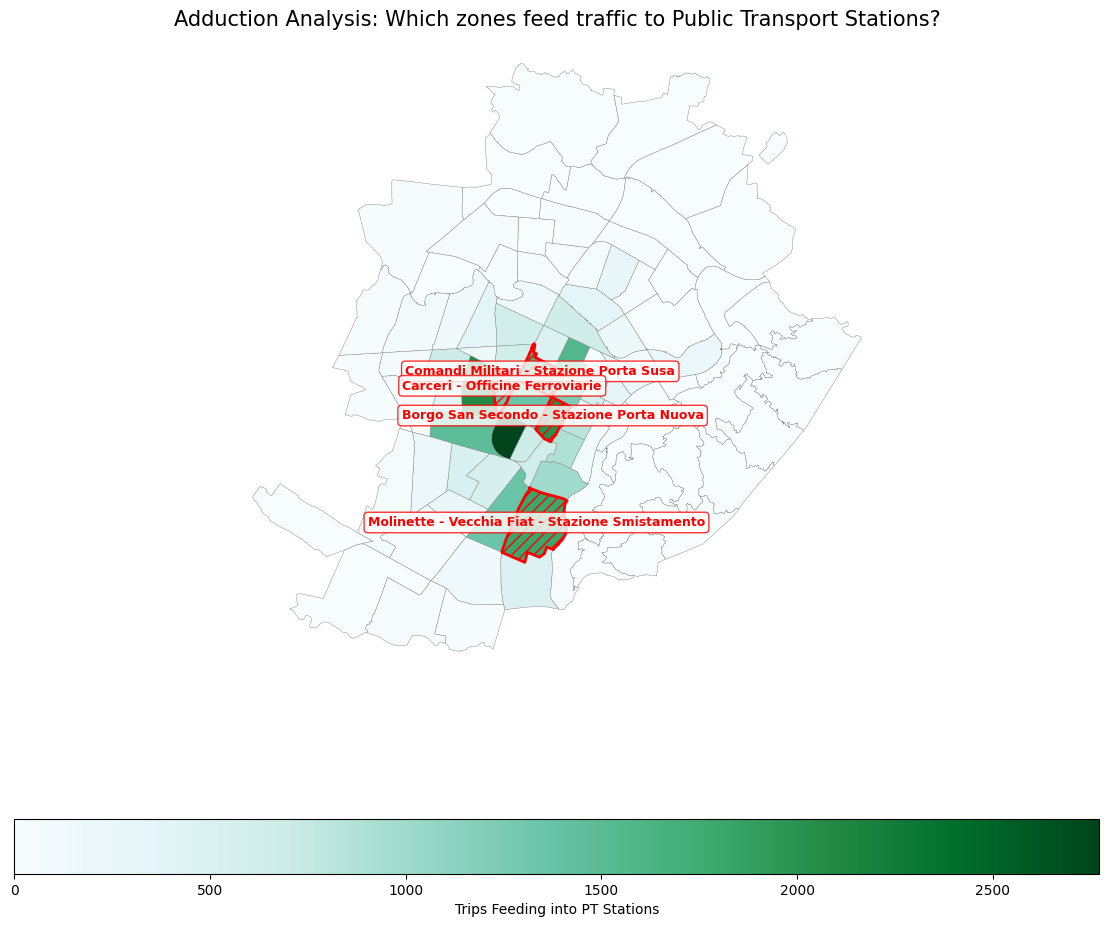

/var/folders/15/_z7w7n_55q3d5xdjvb552jtm0000gn/T/ipykernel_3043/1223568434.py:77: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  to_hub['hour'] = to_hub['start_datetime'].dt.hour
/var/folders/15/_z7w7n_55q3d5xdjvb552jtm0000gn/T/ipykernel_3043/1223568434.py:78: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  from_hub['hour'] = from_hub['start_datetime'].dt.hour


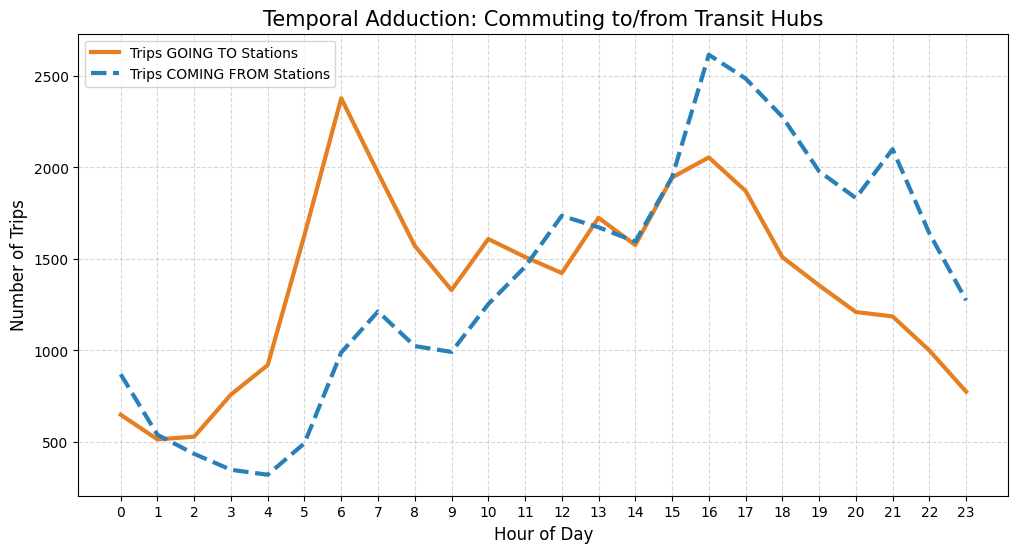

In [74]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

# --- EXERCISE 3: COMPETITION vs ADDUCTION (Corrected) ---

print("🚌 Starting Public Transport Analysis (Adduction vs Competition)...")

# 1. Identify "Public Transport Hub" Zones
# We look for zones containing 'Stazione', 'Porta Nuova', 'Porta Susa', 'Ferrovia'
# Based on your shapefile, names are in the 'DENOM' column.
pt_keywords = ['Stazione', 'Porta Nuova', 'Porta Susa', 'Ferrovia', 'Maddalena']

# Filter zones that act as transit hubs
hub_zones = gdf_zones[gdf_zones['DENOM'].str.contains('|'.join(pt_keywords), case=False, na=False)]
hub_zone_names = hub_zones['DENOM'].unique()

print(f"📍 Identified {len(hub_zone_names)} Public Transport Hub Zones:")
print(hub_zone_names)

# 2. ANALYSIS A: ADDUCTION (Last-Mile Connectivity)
# Trips that START or END at a PT Hub are likely "Adduction" (complementary to PT)
to_hub = df_spatial[df_spatial['end_zone'].isin(hub_zone_names)]
from_hub = df_spatial[df_spatial['start_zone'].isin(hub_zone_names)]

adduction_trips = len(to_hub) + len(from_hub)
adduction_pct = (adduction_trips / len(df_spatial)) * 100

print(f"\n🔄 ADDUCTION INSIGHT:")
print(f"Total trips connecting to Transit Hubs: {adduction_trips} ({adduction_pct:.1f}%)")
print("These trips likely represent 'Last Mile' usage (complementary to PT).")

# 3. ANALYSIS B: POTENTIAL COMPETITION
# Long trips (> 3km) inside the city usually compete with Bus/Metro.
# Short trips (< 1km) compete with Walking.
competition_trips = df_spatial[(df_spatial['distance_km'] > 2.5) & (~df_spatial['start_zone'].isin(hub_zone_names))]

print(f"\n⚔️ COMPETITION INSIGHT:")
print(f"Long distance trips (> 2.5km) NOT connecting to hubs: {len(competition_trips)}")
print("These trips likely compete with Bus/Tram lines.")


# --- PLOT 1: Adduction Heatmap (Trips to/from Stations) ---
print("\n🗺️ Generating Adduction Map...")

# Calculate "Connectivity Score" for each zone (how many trips go to Hubs?)
# We count how many trips from each zone went TO a hub
feeder_trips = to_hub['start_zone'].value_counts().reset_index()
feeder_trips.columns = ['DENOM', 'feeder_count']

# Merge with map
gdf_feeder = gdf_zones.merge(feeder_trips, on='DENOM', how='left').fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(14, 12))

# Plot all zones
gdf_feeder.plot(column='feeder_count', ax=ax, cmap='BuGn', legend=True,
                legend_kwds={'label': "Trips Feeding into PT Stations", 'orientation': "horizontal"},
                edgecolor='gray', linewidth=0.3)

# Highlight the Hubs (Stations) in Red
hub_zones.plot(ax=ax, color='none', edgecolor='red', linewidth=2, hatch='///', label='PT Hubs (Stations)')

# Label the Hubs
for idx, row in hub_zones.iterrows():
    plt.annotate(text=row['DENOM'], xy=(row.geometry.centroid.x, row.geometry.centroid.y),
                 ha='center', fontsize=9, color='red', fontweight='bold', 
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8))

plt.title('Adduction Analysis: Which zones feed traffic to Public Transport Stations?', fontsize=15)
plt.axis('off')
plt.show()


# --- PLOT 2: Hourly Adduction Pattern ---
# Do people go to stations in the morning?
to_hub['hour'] = to_hub['start_datetime'].dt.hour
from_hub['hour'] = from_hub['start_datetime'].dt.hour

hourly_to = to_hub.groupby('hour').size()
hourly_from = from_hub.groupby('hour').size()

plt.figure(figsize=(12, 6))
plt.plot(hourly_to.index, hourly_to.values, label='Trips GOING TO Stations', color='#e67e22', linewidth=3)
plt.plot(hourly_from.index, hourly_from.values, label='Trips COMING FROM Stations', color='#2980b9', linewidth=3, linestyle='--')

plt.title('Temporal Adduction: Commuting to/from Transit Hubs', fontsize=15)
plt.xlabel('Hour of Day', fontsize=12)
plt.ylabel('Number of Trips', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.xticks(range(0, 24))
plt.show()